# US Census MARTS — PM Quickstart

Load the committed April 2026 Advance Monthly Retail Trade Survey file, parse Table 1 (sales by NAICS), and produce a 'category growth at a glance' view a PM can drop in a deck.

**Dataset**: [`samples/census-marts-apr2026.xlsx`](../samples/census-marts-apr2026.xlsx) — public domain.

Source: https://www.census.gov/retail/

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

xls = pd.ExcelFile('../samples/census-marts-apr2026.xlsx')
print('Sheets:', xls.sheet_names)

Sheets: ['Table 1.', 'Table 2.', 'Table 3.']


## 1. Read Table 1 — Estimated Monthly Sales by NAICS

Headers span the top 10 rows. We skip them and label columns manually.

In [2]:
raw = pd.read_excel(xls, sheet_name='Table 1.', header=None)
raw.head(12)

,0,1,2,3,4,5,6,7,8,9,10,11,12,13
0,Table 1. Estimated Monthly Sales for Retail a...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,(Total sales estimates are shown in millions o...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,and administrative records.),NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
5,NaN,NaN,Not Adjusted,NaN,NaN,NaN,NaN,NaN,NaN,Adjusted2,NaN,NaN,NaN,NaN
6,NAICS1,Kind of Business,4 Month Total,NaN,2026,NaN,NaN,2025,NaN,2026,NaN,NaN,2025,NaN
7,code,NaN,NaN,% Chg.,Apr.3,Mar.,Feb.,Apr.,Mar.,Apr.3,Mar.,Feb.,Apr.,Mar.
8,NaN,NaN,2026,2025,(a),(p),(r),NaN,NaN,(a),(p),(r),(r),(r)
9,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [3]:
# Data begins at row 10. The Census xlsx uses '(*)' and '(NA)' for suppressed values.
data = raw.iloc[10:].copy()
data.columns = [
    'NAICS',
    'KindOfBusiness',
    'TotalSales_4mo_2026',
    'PctChg_vs2025',
    'Apr_2026_NSA_adv',
    'Mar_2026_NSA_prelim',
    'Feb_2026_NSA_revised',
    'Apr_2025_NSA',
    'Mar_2025_NSA_revised',
    'Apr_2026_SA_adv',
    'Mar_2026_SA_prelim',
    'Feb_2026_SA_revised',
    'Apr_2025_SA',
    'Mar_2025_SA_revised',
]

# Coerce numeric columns; '(*)' and '(NA)' become NaN
numeric_cols = [c for c in data.columns if c not in ('NAICS', 'KindOfBusiness')]
for c in numeric_cols:
    data[c] = pd.to_numeric(data[c], errors='coerce')

data['KindOfBusiness'] = data['KindOfBusiness'].astype(str).str.replace(r'[…\.]+', '', regex=True).str.strip()
data = data[data['KindOfBusiness'].notna() & (data['KindOfBusiness'] != 'nan') & (data['KindOfBusiness'] != '')].reset_index(drop=True)
data.head(10)

,NAICS,KindOfBusiness,TotalSales_4mo_2026,PctChg_vs2025,Apr_2026_NSA_adv,Mar_2026_NSA_prelim,Feb_2026_NSA_revised,Apr_2025_NSA,Mar_2025_NSA_revised,Apr_2026_SA_adv,Mar_2026_SA_prelim,Feb_2026_SA_revised,Apr_2025_SA,Mar_2025_SA_revised
0,NaN,"Retail & food services,",NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,NaN,total,2846941.0,4.1,755713.0,760772.0,656082.0,722319.0,726888.0,757085.0,753370.0,741278.0,721903.0,723339.0
2,NaN,Total (excl motor vehicle & parts),2301792.0,5.1,609628.0,611382.0,529523.0,574654.0,574454.0,617856.0,613556.0,602258.0,581040.0,581017.0
3,NaN,Total (excl gasoline stations),2633737.0,3.7,693217.0,701758.0,610900.0,670770.0,676367.0,695573.0,693518.0,688618.0,671016.0,671997.0
4,NaN,Total (excl motor vehicle & parts &,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
5,NaN,gasoline stations),2088588.0,4.7,547132.0,552368.0,484341.0,523105.0,523933.0,556344.0,553704.0,549598.0,530153.0,529675.0
6,NaN,Retail,2458520.0,4.2,654238.0,657332.0,564663.0,623756.0,624954.0,656115.0,653040.0,641038.0,623635.0,625420.0
7,NaN,GAFO4,NaN,NaN,NaN,133661.0,115513.0,125740.0,128550.0,NaN,137056.0,135616.0,131599.0,132264.0
8,441,Motor vehicle & parts dealers,545149.0,0.0,146085.0,149390.0,126559.0,147665.0,152434.0,139229.0,139814.0,139020.0,140863.0,142322.0
9,"4411, 4412",Auto & other motor veh dealers,499879.0,-0.2,134073.0,137244.0,116146.0,135856.0,140668.0,127567.0,128146.0,127214.0,129387.0,130854.0


## 2. Year-over-year growth by category

Using seasonally adjusted columns.

In [4]:
data['YoY_pct'] = (data['Apr_2026_SA_adv'] - data['Apr_2025_SA']) / data['Apr_2025_SA'] * 100
g = data.dropna(subset=['Apr_2026_SA_adv', 'Apr_2025_SA', 'YoY_pct']).copy()
g = g.sort_values('YoY_pct', ascending=False)
g[['NAICS', 'KindOfBusiness', 'Apr_2026_SA_adv', 'Apr_2025_SA', 'YoY_pct']].head(15)

,NAICS,KindOfBusiness,Apr_2026_SA_adv,Apr_2025_SA,YoY_pct
24,447,Gasoline stations,61512.0,50887.0,20.879596
32,NaN,"instrument, & book stores",8773.0,7734.0,13.434187
39,453,Miscellaneous store retailers,15942.0,14133.0,12.799830
40,454,Nonstore retailers,137558.0,123854.0,11.064641
15,443,Electronics & appliance stores,8174.0,7595.0,7.623436
2,NaN,Total (excl motor vehicle & parts),617856.0,581040.0,6.336225
26,NaN,stores,27534.0,26103.0,5.482128
6,NaN,Retail,656115.0,623635.0,5.208175
5,NaN,gasoline stations),556344.0,530153.0,4.940272
1,NaN,total,757085.0,721903.0,4.873508


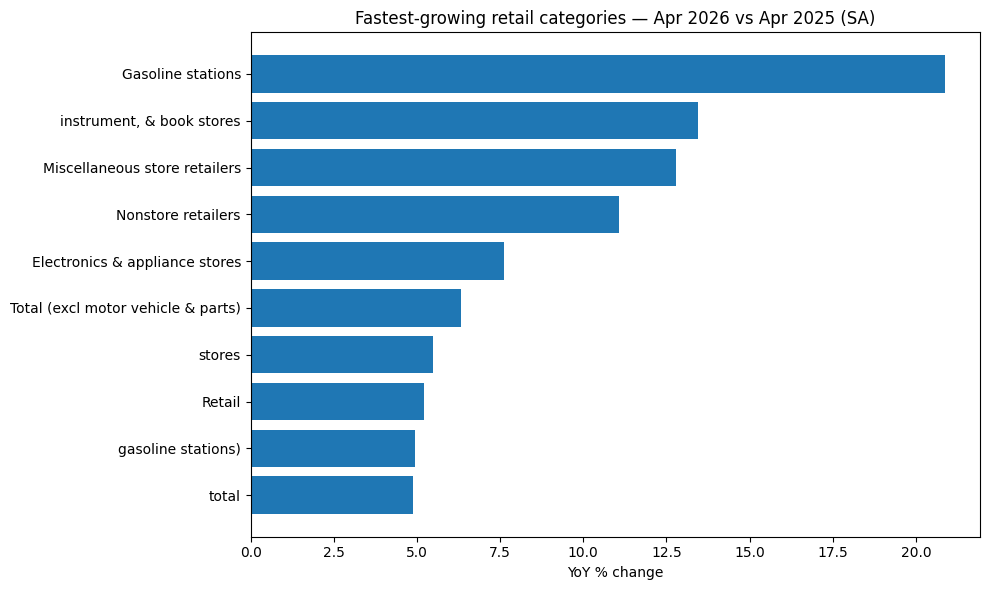

In [5]:
top10 = g.head(10)
fig, ax = plt.subplots(figsize=(10, 6))
ax.barh(top10['KindOfBusiness'], top10['YoY_pct'])
ax.invert_yaxis()
ax.set_xlabel('YoY % change')
ax.set_title('Fastest-growing retail categories — Apr 2026 vs Apr 2025 (SA)')
plt.tight_layout()
plt.show()

## What to try next
- Download a full history (all MARTS releases 2010-present) → time series.
- Compare your business unit's YoY to the NAICS line you compete in (NAICS 4541 = electronic shopping / mail-order).
- Read [`scorecards/04-forecasting-accuracy.md`](../scorecards/04-forecasting-accuracy.md) — Census is the macro anchor for forecast reconciliation.